# Loan Approval Prediction

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Data Loading

In [4]:
DATA_PATH = Path("../data/raw/loan_data.csv")

df = pd.read_csv(DATA_PATH)

df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


# EDA

### Data Information

In [5]:
print("Shape:", df.shape)

Shape: (45000, 14)


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  45000 non-n

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,45000.0,27.764178,6.045108,20.00,24.00,26.00,30.00,144.00
person_income,45000.0,80319.053222,80422.498632,8000.00,47204.00,67048.00,95789.25,7200766.00
person_emp_exp,45000.0,5.410333,6.063532,0.00,1.00,4.00,8.00,125.00
loan_amnt,45000.0,9583.157556,6314.886691,500.00,5000.00,8000.00,12237.25,35000.00
loan_int_rate,45000.0,11.006606,2.978808,5.42,8.59,11.01,12.99,20.00
loan_percent_income,45000.0,0.139725,0.087212,0.00,0.07,0.12,0.19,0.66
cb_person_cred_hist_length,45000.0,5.867489,3.879702,2.00,3.00,4.00,8.00,30.00
credit_score,45000.0,632.608756,50.435865,390.00,601.00,640.00,670.00,850.00
loan_status,45000.0,0.222222,0.415744,0.00,0.00,0.00,0.00,1.00


In [9]:
df.describe(include="object").T

C:\Users\13ver\AppData\Local\Temp\ipykernel_2616\1274302342.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T


,count,unique,top,freq
person_gender,45000,2,male,24841
person_education,45000,5,Bachelor,13399
person_home_ownership,45000,4,RENT,23443
loan_intent,45000,6,EDUCATION,9153
previous_loan_defaults_on_file,45000,2,Yes,22858


### Missing Values

In [10]:
df.isnull().sum(),
round(df.isnull().mean()*100,2)

person_age                        0.0
person_gender                     0.0
person_education                  0.0
person_income                     0.0
person_emp_exp                    0.0
person_home_ownership             0.0
loan_amnt                         0.0
loan_intent                       0.0
loan_int_rate                     0.0
loan_percent_income               0.0
cb_person_cred_hist_length        0.0
credit_score                      0.0
previous_loan_defaults_on_file    0.0
loan_status                       0.0
dtype: float64

### Duplicate Rows

In [17]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


### Check Invalid Values

In [18]:
print("Age > 100:", (df["person_age"] > 100).sum())
print("Negative Income:", (df["person_income"] < 0).sum())
print("Negative Loan:", (df["loan_amnt"] < 0).sum())
print("Exp > Age:", (df["person_emp_exp"] > df["person_age"]).sum())

Age > 100: 7
Negative Income: 0
Negative Loan: 0
Exp > Age: 0


### Separate Columns

In [15]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns
cat_cols = df.select_dtypes(include=["object"]).columns

print("Numerical Columns:", num_cols)
print("Categorical Columns:", cat_cols)

Numerical Columns: Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'loan_status'],
      dtype='str')
Categorical Columns: Index(['person_gender', 'person_education', 'person_home_ownership',
       'loan_intent', 'previous_loan_defaults_on_file'],
      dtype='str')


C:\Users\13ver\AppData\Local\Temp\ipykernel_2616\1454362221.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object"]).columns


### Target Variable Analysis

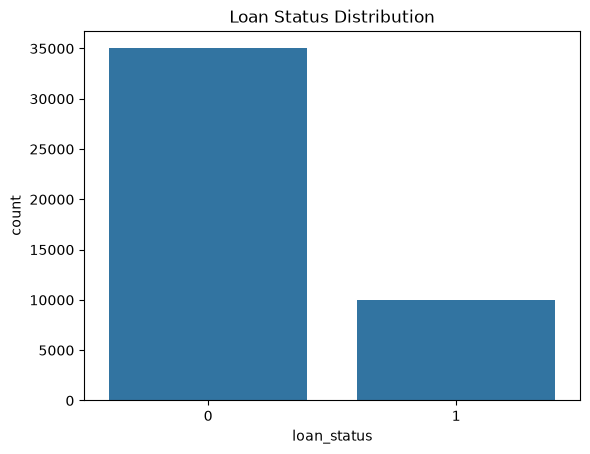

In [ ]:
df["loan_status"].value_counts()
round(df["loan_status"].value_counts(normalize=True)*100, 2)

sns.countplot(x=df["loan_status"])
plt.title("Loan Status Distribution")
plt.show()

### Numerical Feature Distribution

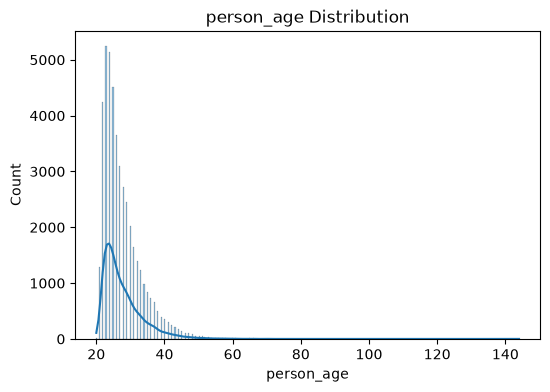

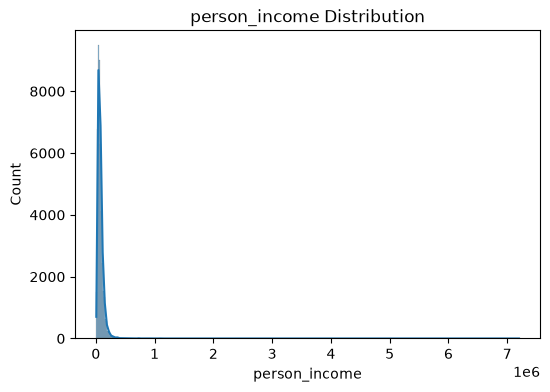

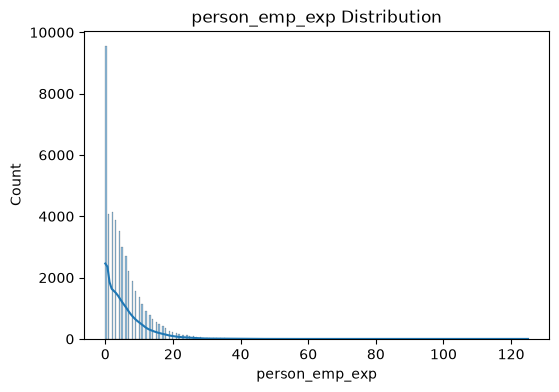

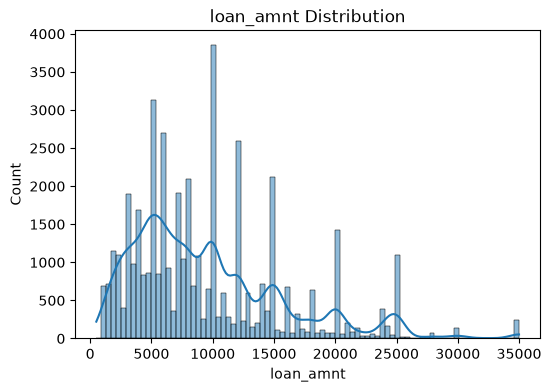

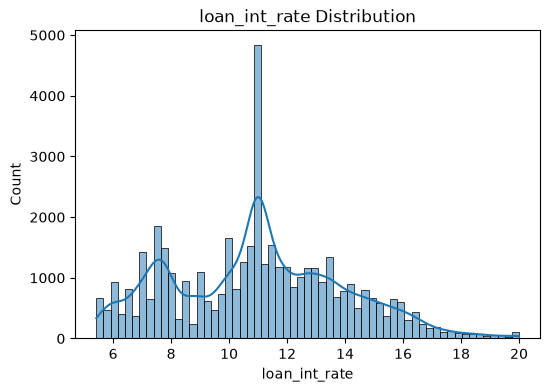

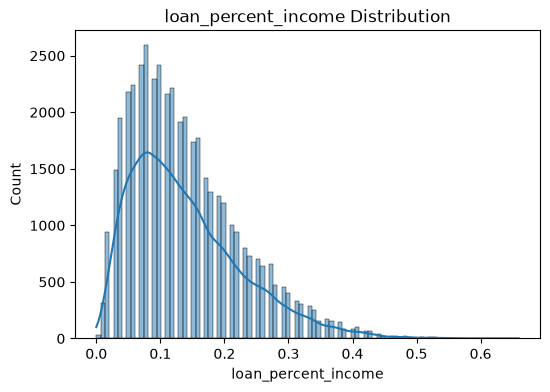

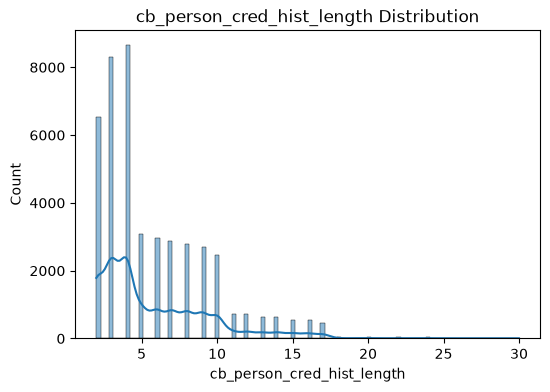

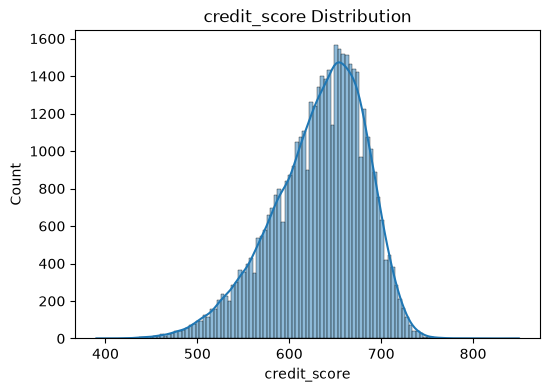

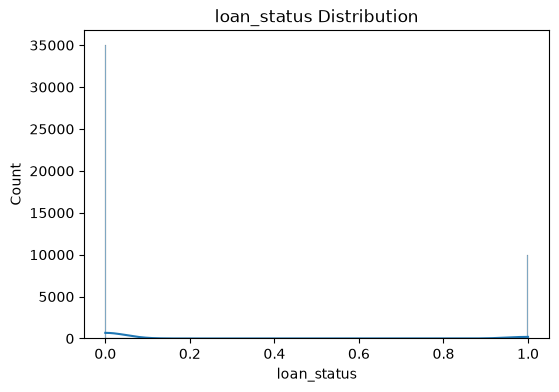

In [44]:
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True)
    plt.title(f"{col} Distribution")
    plt.show()

### Outlier Detection

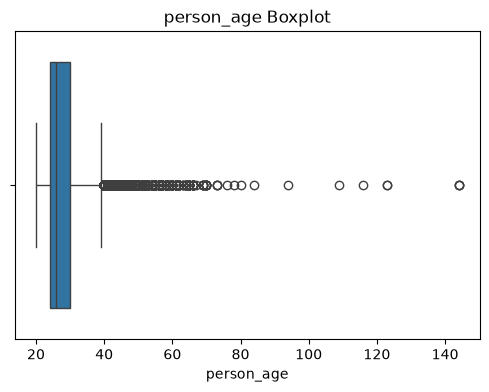

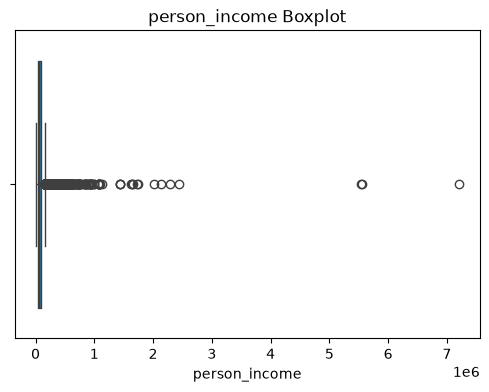

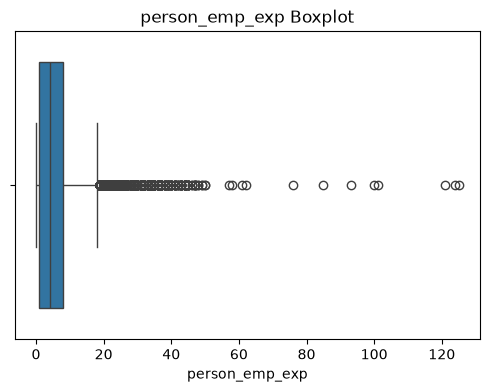

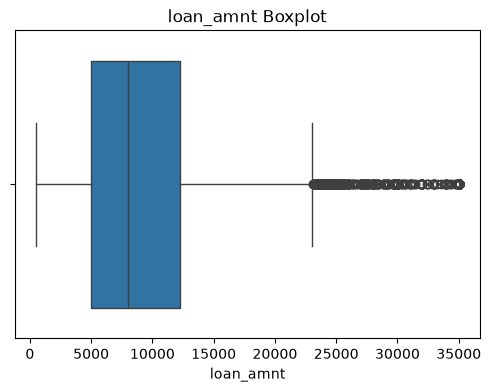

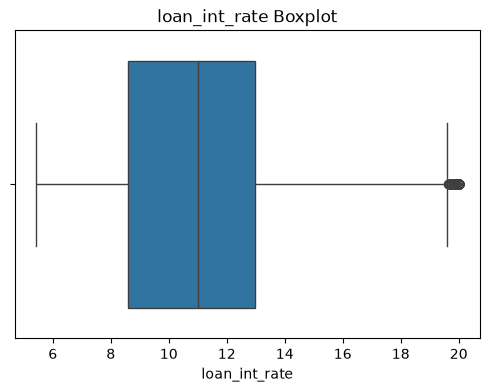

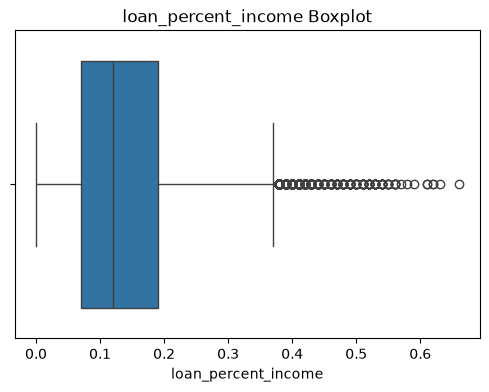

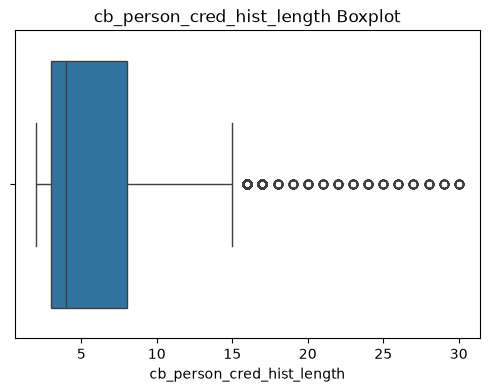

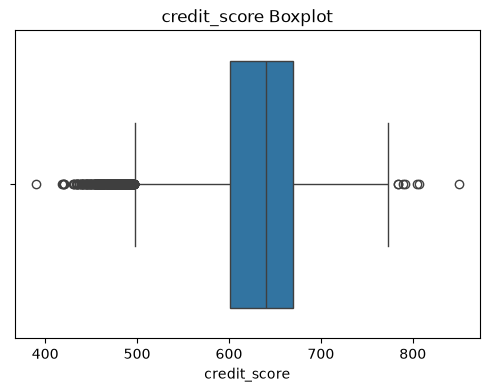

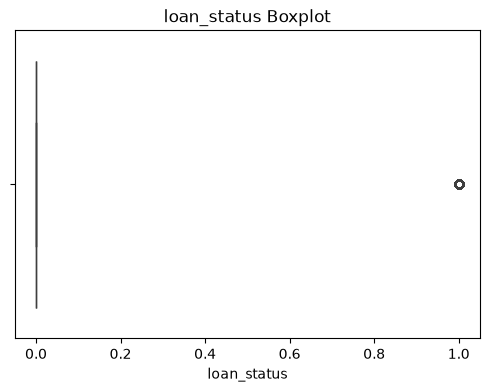

In [32]:
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"{col} Boxplot")
    plt.show()

### Categorical Feature Distribution

In [ ]:
for col in cat_cols:
    print(f"\n{col}")
    print(df[col].value_counts())

    df[col].value_counts().plot(kind="bar")
    plt.title(col)
    plt.show()

### Relationship with Target

#### Numerical vs Target

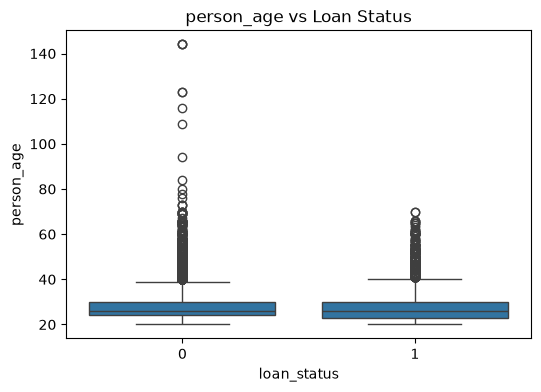

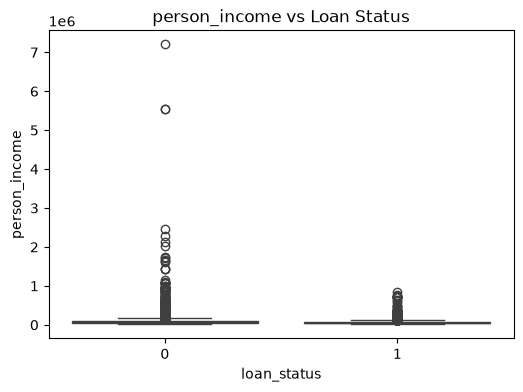

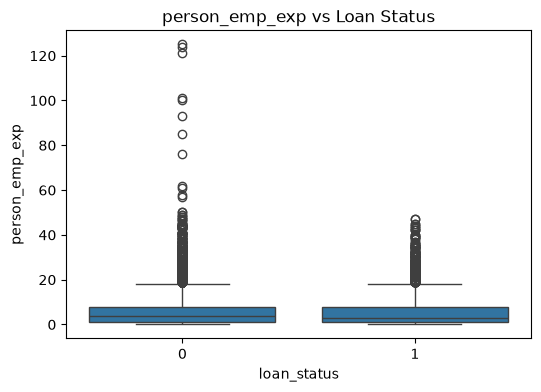

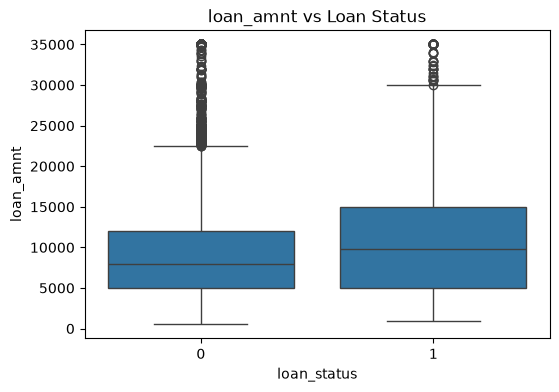

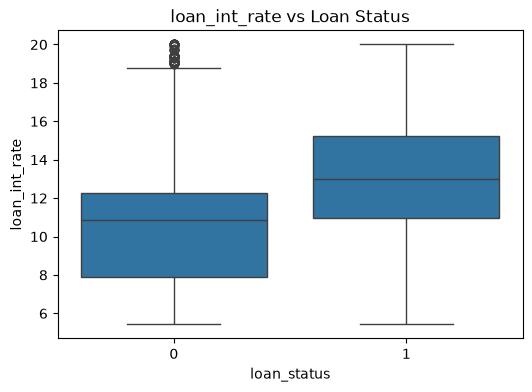

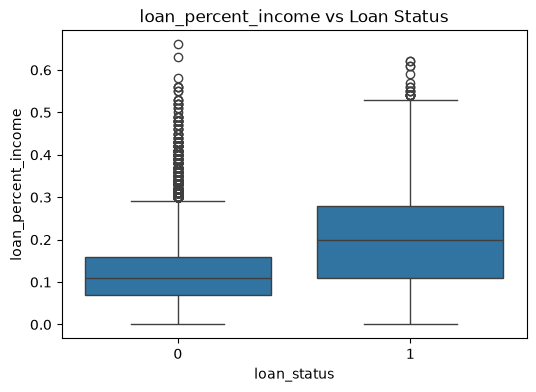

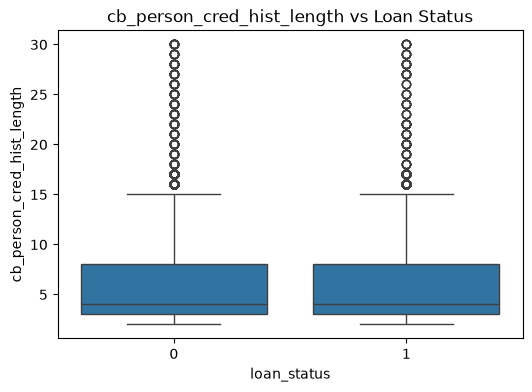

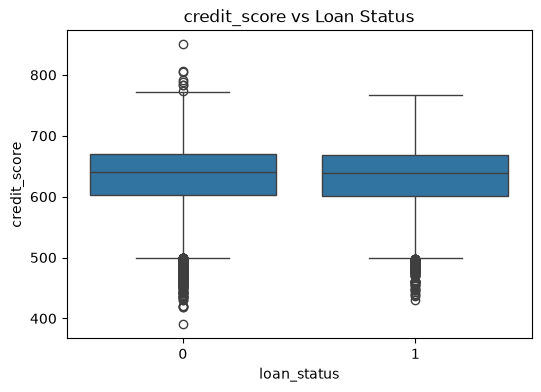

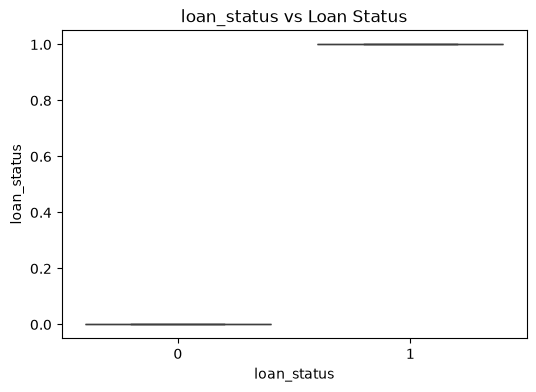

In [36]:
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x="loan_status", y=col, data=df)
    plt.title(f"{col} vs Loan Status")
    plt.show()

#### Categorical vs Target


person_gender
loan_status           0         1
person_gender                    
female         0.777519  0.222481
male           0.777988  0.222012


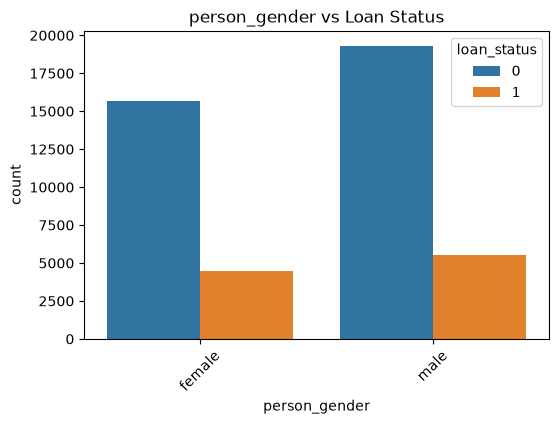


person_education
loan_status              0         1
person_education                    
Associate         0.779681  0.220319
Bachelor          0.774759  0.225241
Doctorate         0.771337  0.228663
High School       0.776896  0.223104
Master            0.782378  0.217622


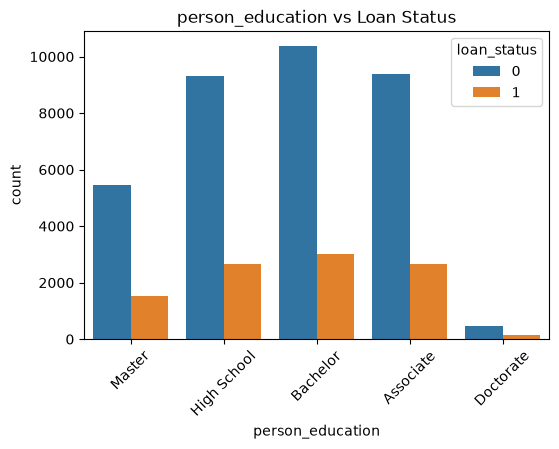


person_home_ownership
loan_status                   0         1
person_home_ownership                    
MORTGAGE               0.884039  0.115961
OTHER                  0.666667  0.333333
OWN                    0.924771  0.075229
RENT                   0.676023  0.323977


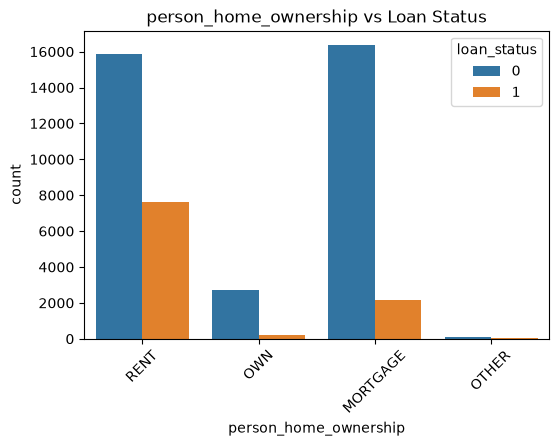


loan_intent
loan_status               0         1
loan_intent                          
DEBTCONSOLIDATION  0.697271  0.302729
EDUCATION          0.830438  0.169562
HOMEIMPROVEMENT    0.736985  0.263015
MEDICAL            0.721806  0.278194
PERSONAL           0.798596  0.201404
VENTURE            0.855736  0.144264


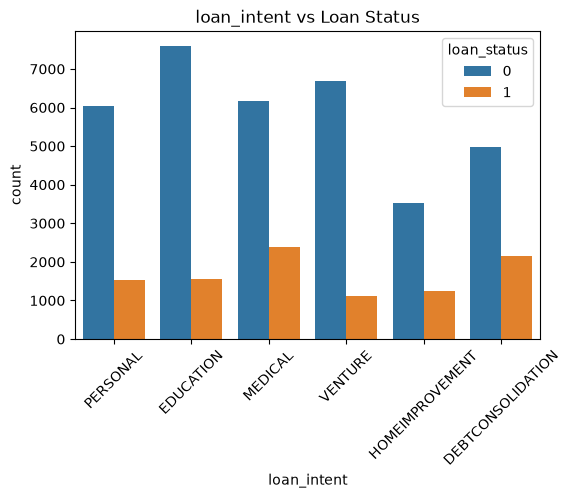


previous_loan_defaults_on_file
loan_status                           0        1
previous_loan_defaults_on_file                  
No                              0.54837  0.45163
Yes                             1.00000  0.00000


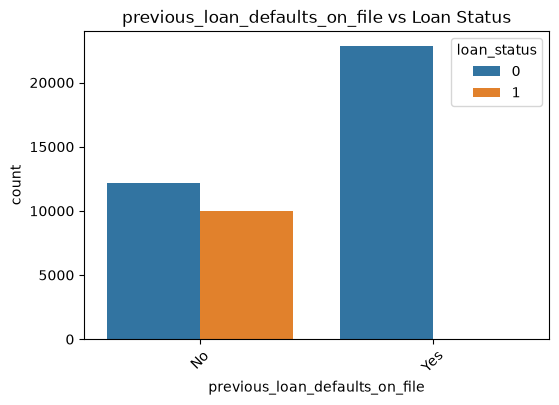

In [42]:
for col in cat_cols:
    print(f"\n{col}")
    print(pd.crosstab(df[col], df["loan_status"], normalize="index"))

    plt.figure(figsize=(6,4))
    sns.countplot(x=col, hue="loan_status", data=df)
    plt.title(f"{col} vs Loan Status")
    plt.xticks(rotation=45)
    plt.show()

### Correlation Analysis

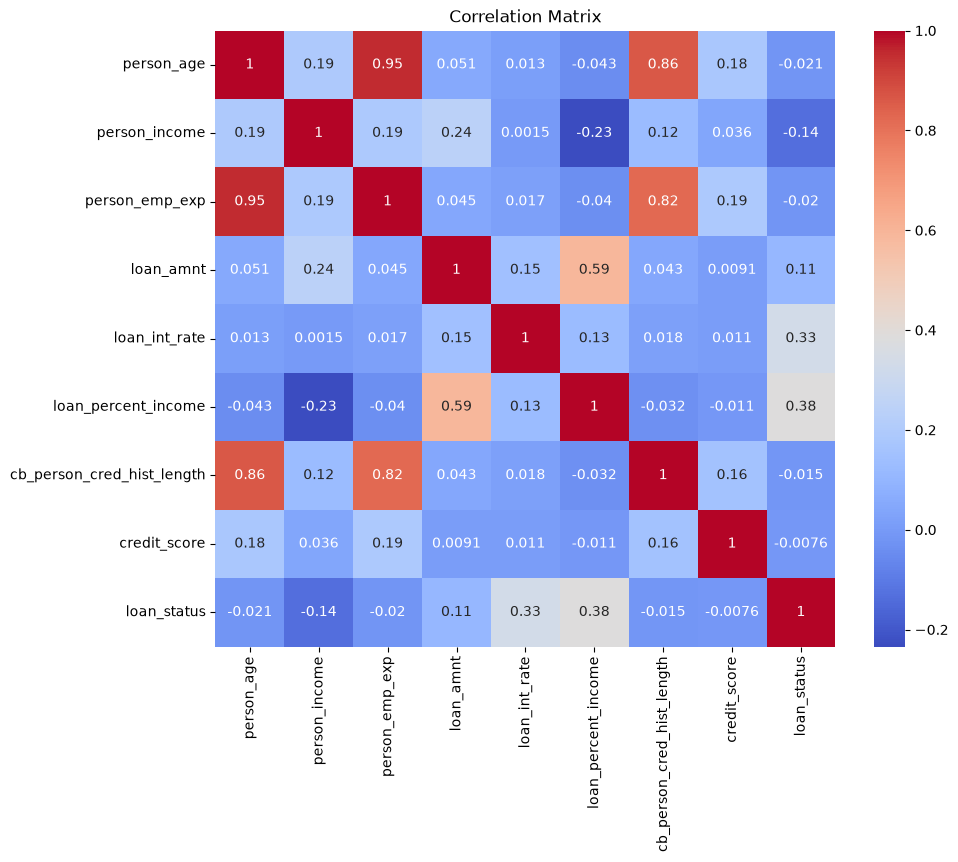

In [43]:
corr = df[num_cols].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

# Data Preprocessing

### Handle Invalid Age

In [45]:
df = df[df["person_age"] <= 100]

In [46]:
print("Age > 100:", (df["person_age"] > 100).sum())
print("Negative Income:", (df["person_income"] < 0).sum())
print("Negative Loan:", (df["loan_amnt"] < 0).sum())
print("Exp > Age:", (df["person_emp_exp"] > df["person_age"]).sum())

Age > 100: 0
Negative Income: 0
Negative Loan: 0
Exp > Age: 0


### Feature & Target Split

In [48]:
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

print("Features and Target separated")

Features and Target separated


### Encode Categorical Columns

In [52]:
X = pd.get_dummies(X, drop_first=True)

### Train-Test Split

In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

### Feature Scaling

In [54]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Model Training

In [56]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)
model.fit(X_train, y_train)
print("Training Completed")

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

Training Completed


In [57]:
print(f"Model       : {model.__class__.__name__}")
print(f"Criterion   : {model.criterion}")
print(f"Max depth   : {model.get_depth()}")
print(f"Leaf nodes  : {model.get_n_leaves()}")
print(f"Features    : {model.n_features_in_}")
print(f"Classes     : {list(model.classes_)}")

Model       : DecisionTreeClassifier
Criterion   : gini
Max depth   : 5
Leaf nodes  : 15
Features    : 22
Classes     : [np.int64(0), np.int64(1)]


# Model Evaluation

In [60]:
metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1_score": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_proba),
}

print(f"Accuracy    : {metrics['accuracy']:.4f}")
print(f"Precision   : {metrics['precision']:.4f}")
print(f"Recall      : {metrics['recall']:.4f}")
print(f"F1 Score    : {metrics['f1_score']:.4f}")
print(f"ROC AUC     : {metrics['roc_auc']:.4f}")

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy    : 0.9098
Precision   : 0.8557
Recall      : 0.7145
F1 Score    : 0.7787
ROC AUC     : 0.9534

Confusion Matrix:
[[6758  241]
 [ 571 1429]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      6999
           1       0.86      0.71      0.78      2000

    accuracy                           0.91      8999
   macro avg       0.89      0.84      0.86      8999
weighted avg       0.91      0.91      0.91      8999



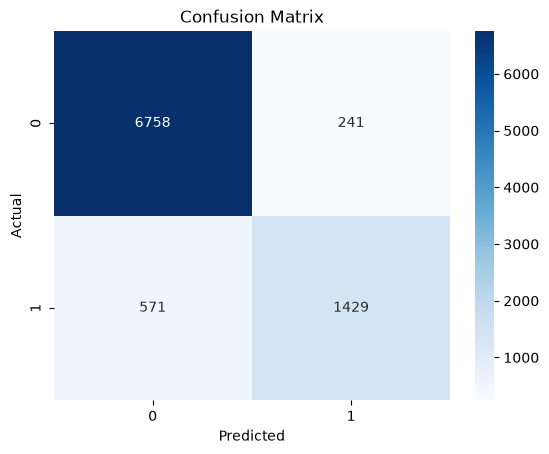

In [62]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Save Model

In [61]:
import joblib
joblib.dump(model, "../saved_models/load_model.pkl")

['../saved_models/load_model.pkl']

# Predictions

In [78]:
new_data = pd.DataFrame([{
    "person_age": 30,
    "person_income": 60000,
    "person_emp_exp": 5,
    "loan_amnt": 15000,
    "loan_intent": "PERSONAL",
    "loan_grade": "B",
    "person_home_ownership": "RENT",
    "loan_int_rate": 12.5,
    "loan_percent_income": 0.25,
    "cb_person_default_on_file": "N",
    "cb_person_cred_hist_length": 4
}])

### Align with training features

In [79]:
new_data = pd.get_dummies(new_data)


### Encode

In [80]:
new_data = new_data.reindex(columns=X.columns, fill_value=0)

### Scale

In [81]:
new_data = scaler.transform(new_data)

### Predict

In [82]:
prediction = model.predict(new_data)
probability = model.predict_proba(new_data)

In [76]:
if prediction[0] == 1:
    print("Loan Approved")
else:
    print("Loan Rejected")

print("Approval Probability:", probability[0][1])

Loan Approved
Approval Probability: 0.7884615384615384
